In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv('../data/processed/final_dataset.csv')
print(f'Shape: {df.shape}')
df.head()

Shape: (30000, 36)


,url,label,url_length,hostname_length,nb_dots,nb_hyphens,nb_slash,nb_at,nb_qmark,nb_equal,...,domain_age_days,domain_registration_length,dns_record,nb_hyperlinks,ratio_internal_links,nb_external_css,has_login_form,has_iframe,external_favicon,title_matches_domain
0,http://yaho-world-wandering-limit-8b7e.yorzeko...,1,61,54,3,4,2,0,0,0,...,-1,-1,0,2,0.000,1,0,0,0,0
1,https://westlaw.com,0,19,11,1,0,2,0,0,0,...,-1,-1,0,1,1.000,0,0,0,0,0
2,https://google.mg,0,17,9,1,0,2,0,0,0,...,-1,-1,0,20,0.250,1,0,0,0,1
3,https://charlotte.edu,0,21,13,1,0,2,0,0,0,...,-1,-1,0,94,0.862,2,0,0,0,1
4,https://mesesemondre.web.app,1,28,20,2,0,2,0,0,0,...,-1,-1,0,2,0.000,1,0,0,0,0


C:\Users\TANISH N JAY\AppData\Local\Temp\ipykernel_25264\2316389761.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df, palette=['#2ecc71', '#e74c3c'])
C:\Users\TANISH N JAY\AppData\Local\Temp\ipykernel_25264\2316389761.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


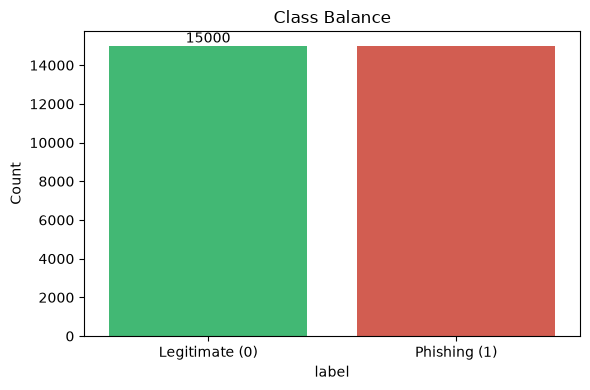

class_balance.png is saved.


<Figure size 640x480 with 0 Axes>

class_balance.png is saved.


In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df, palette=['#2ecc71', '#e74c3c'])
ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
plt.title('Class Balance')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(F'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom')
    plt.tight_layout()
    plt.savefig('../results/class_balance.png', dpi=150)
    plt.show()
    print('class_balance.png is saved.')

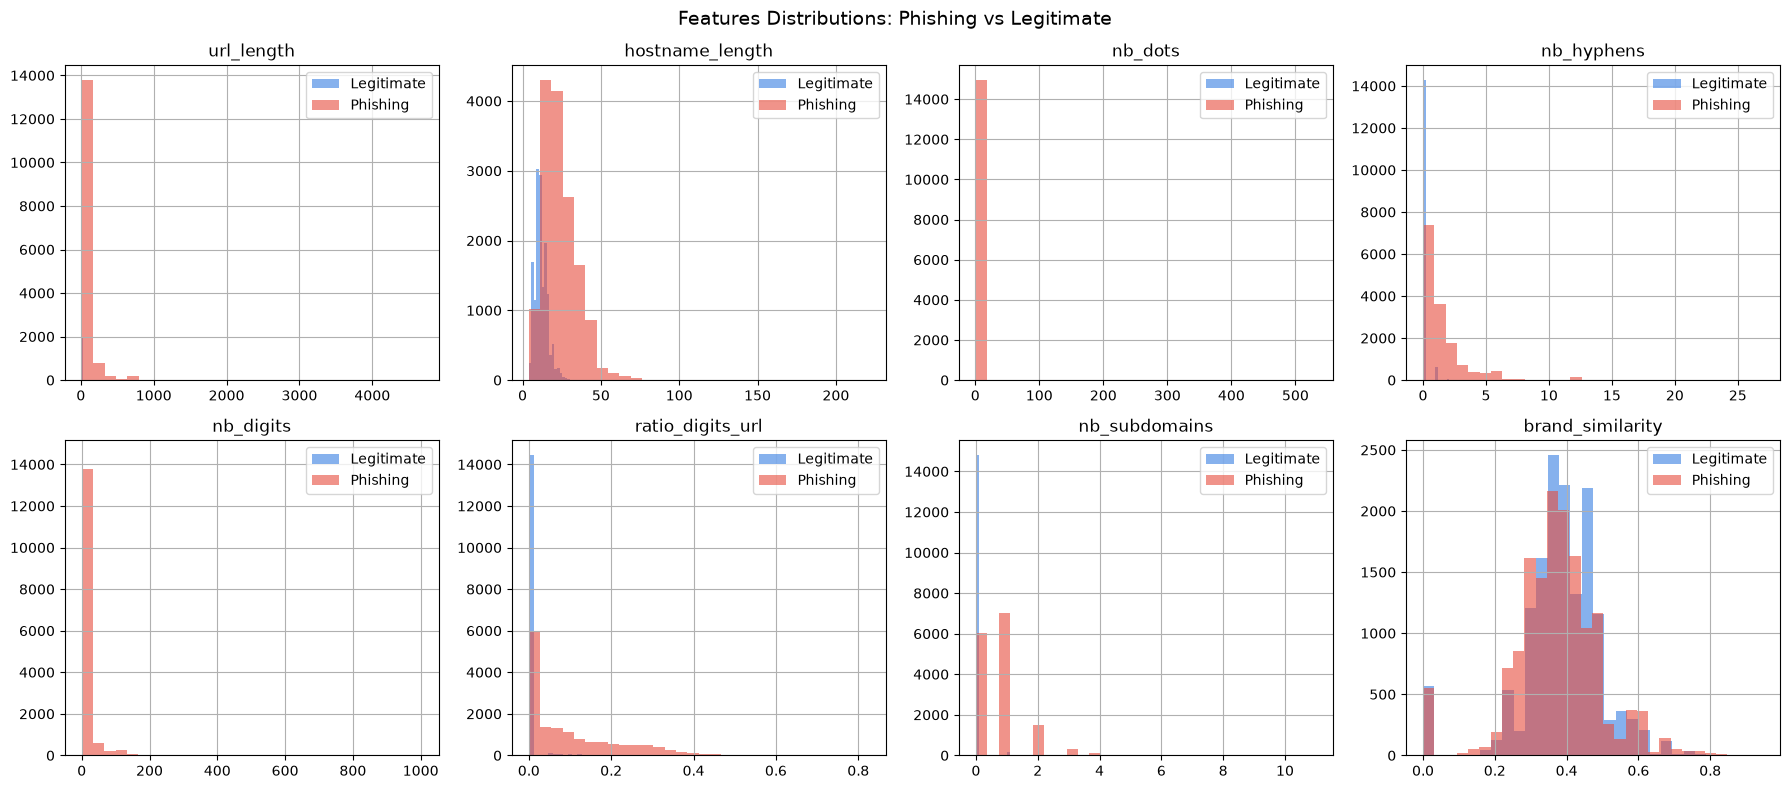

feature_distributions.png saved!


In [7]:
features = [
    'url_length', 'hostname_length', 'nb_dots', 'nb_hyphens',
    'nb_digits', 'ratio_digits_url', 'nb_subdomains', 'brand_similarity'
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, feat in enumerate(features):
    if feat in df.columns:
        df[df['label'] == 0][feat].hist(ax=axes[i], alpha=0.6, color="#357de2", label='Legitimate', bins=30)
        df[df['label'] == 1][feat].hist(ax=axes[i], alpha=0.6, color='#e74c3c', label='Phishing', bins=30)
        axes[i].set_title(feat)
        axes[i].legend()

plt.suptitle('Features Distributions: Phishing vs Legitimate', fontsize=14)
plt.tight_layout()
plt.savefig('../results/feature_distributions.png', dpi=150)
plt.show()
print('feature_distributions.png saved!')

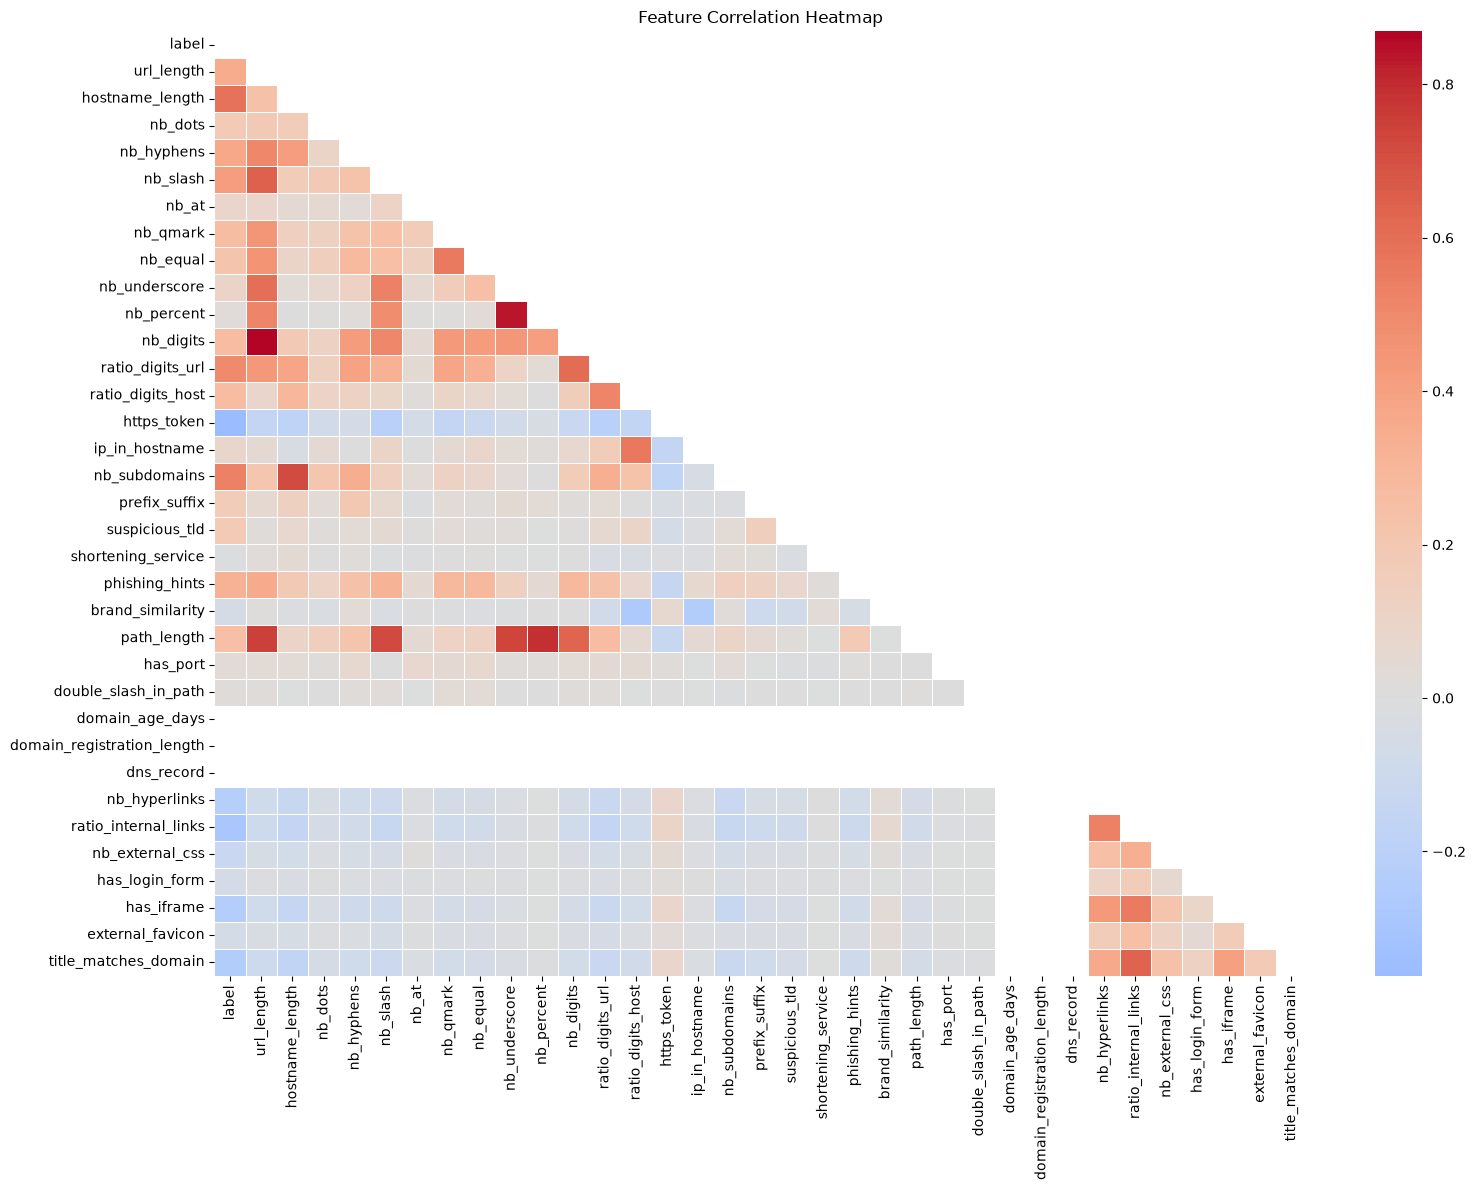

Saved


In [9]:
numeric_df = df.drop(columns=['url']).copy()

plt.figure(figsize=(16, 12))
corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0,
            linewidths=0.5, annot=False)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('../results/correlation_heatmap.png', dpi=200)
plt.show()
print('Saved')

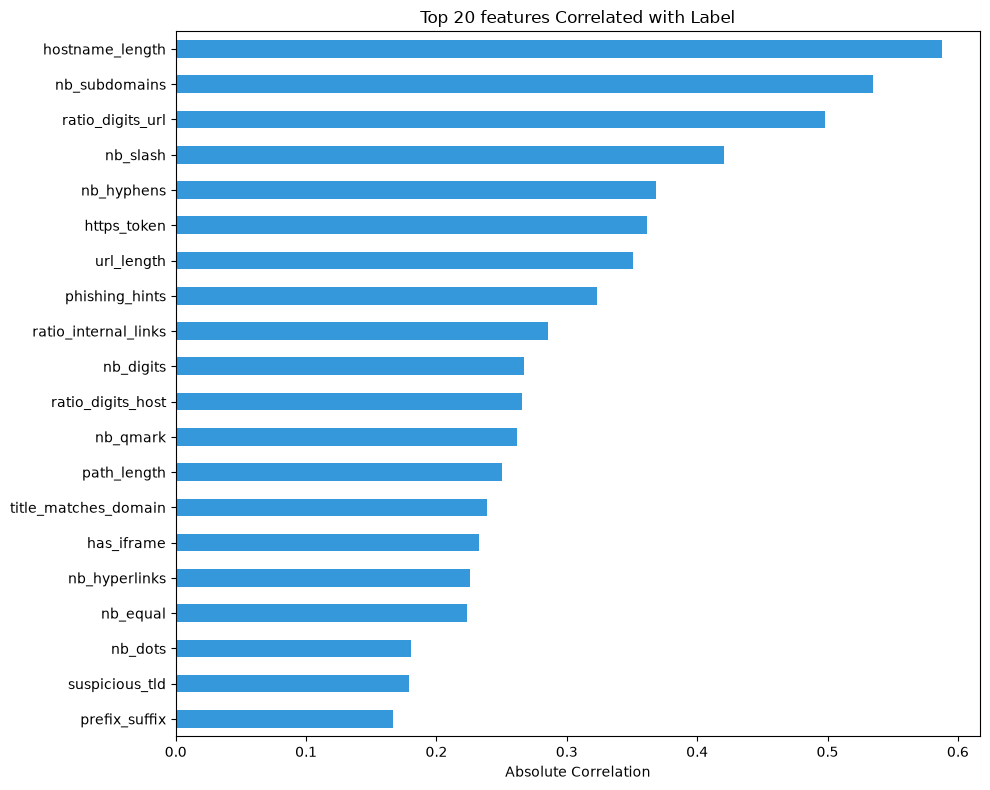

Top 10 features:
hostname_length         0.587587
nb_subdomains           0.534776
ratio_digits_url        0.498351
nb_slash                0.420235
nb_hyphens              0.368361
https_token             0.361774
url_length              0.351114
phishing_hints          0.323002
ratio_internal_links    0.285590
nb_digits               0.267167
Name: label, dtype: float64


In [12]:
target_corr = numeric_df.corr()['label'].drop('label').abs().sort_values(ascending=False)

plt.figure(figsize=(10, 8))
target_corr.head(20).sort_values().plot(kind='barh', color='#3498db')
plt.title('Top 20 features Correlated with Label')
plt.xlabel('Absolute Correlation')
plt.tight_layout()
plt.savefig('../results/top_correlated_features.png', dpi=150)
plt.show()

print('Top 10 features:')
print(target_corr.head(10))